# PingGuard v2.0 — Complete End-to-End SMS Spam Detection & Safety Pipeline

This standalone notebook contains the full implementation of **PingGuard v2.0**:
1. **Dataset Acquisition & Cleaning:** Official UCI SMS Spam Collection (ID 228), label normalization, and exact duplicate removal.
2. **Exploratory Data Analysis (EDA):** Class distribution, message length patterns, and top frequent spam/ham terms.
3. **v1.0 Baseline Benchmark:** Word-only TF-IDF + Random Forest (0.50 cutoff) for Before vs. After comparison.
4. **Hybrid Feature Engineering:** Word TF-IDF (unigrams/bigrams) + Character N-Grams (3–5 chars) to catch obfuscated spam.
5. **8 Supervised & Ensemble Classifiers + Threshold Tuning:** Entropy Decision Tree, Logistic Regression, Calibrated Linear SVM, Random Forest, AdaBoost, Gradient Boosting, XGBoost, and Weighted Soft-Voting Meta-Ensemble.
6. **Unsupervised Learning:** PCA 2D visualization and K-Means Clustering (Elbow Method) for spam theme discovery.
7. **Reinforcement Learning & AI Ethics:** Q-Learning adaptive policy agent (Allow / Quarantine / Block) with Bellman update and FPR/FNR audit.
8. **Live Screening Demo:** Multi-case testing (Ham, Phishing Spam, and Obfuscated Spam) with rule-based warning signs.

In [1]:
import re
import json
import zipfile
import inspect
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import joblib
from scipy.sparse import hstack
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATASET_DIR = BASE_DIR / 'dataset'
MODELS_DIR = BASE_DIR / 'models'
REPORTS_DIR = BASE_DIR / 'reports'
for d in [DATASET_DIR, MODELS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print('Workspace ready at:', BASE_DIR)

Workspace ready at: C:\Bhavesh\TY B.Tech\SEM V\ML_LAB\ml mini project\pingguard - Copy


## 1. Dataset Acquisition, Schema Inspection & Deduplication
We load the official **UCI SMS Spam Collection (ID 228)** and remove exact duplicates before splitting to prevent train/test data leakage.

In [2]:
def load_sms_dataset():
    local_tsv = DATASET_DIR / 'SMSSpamCollection'
    local_csv = DATASET_DIR / 'sms_spam_raw.csv'
    if local_tsv.exists():
        return pd.read_csv(local_tsv, sep='\t', header=None, names=['label', 'message'], quoting=3, encoding='utf-8')
    if local_csv.exists():
        return pd.read_csv(local_csv)
    try:
        from ucimlrepo import fetch_ucirepo
        repo = fetch_ucirepo(id=228)
        df_tmp = pd.concat([repo.data.targets, repo.data.features], axis=1)
        df_tmp.to_csv(local_csv, index=False)
        return df_tmp
    except Exception:
        url = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
        zpath = DATASET_DIR / 'sms_spam_collection.zip'
        urllib.request.urlretrieve(url, zpath)
        with zipfile.ZipFile(zpath, 'r') as zf:
            zf.extract('SMSSpamCollection', path=DATASET_DIR)
        return pd.read_csv(local_tsv, sep='\t', header=None, names=['label', 'message'], quoting=3, encoding='utf-8')

df_raw = load_sms_dataset()
print('Raw Shape:', df_raw.shape)
display(df_raw.head())

# Dynamic column normalization
df = df_raw.copy()
label_col, msg_col = None, None
for col in df.columns:
    uvals = set(df[col].dropna().astype(str).str.strip().str.lower().unique())
    if uvals.issubset({'ham', 'spam', '0', '1'}) and len(uvals) >= 2:
        label_col = col
    elif msg_col is None:
        msg_col = col
df = df[[label_col, msg_col]].rename(columns={label_col: 'label', msg_col: 'message'}).dropna()
df['label'] = df['label'].astype(str).str.strip().str.lower().map({'0': 'ham', '1': 'spam', 'ham': 'ham', 'spam': 'spam'})
df = df[df['label'].isin(['ham', 'spam'])].copy()
df['message'] = df['message'].astype(str).str.strip()
df = df[df['message'].str.len() > 0].copy()

dup_count = int(df.duplicated(subset=['label', 'message']).sum())
df_clean = df.drop_duplicates(subset=['label', 'message'], keep='first').reset_index(drop=True)
df_clean['target'] = (df_clean['label'] == 'spam').astype(int)
df_clean['char_length'] = df_clean['message'].str.len()
df_clean['word_count'] = df_clean['message'].str.split().str.len()

print(f'Exact duplicates removed: {dup_count}')
print(f'Cleaned dataset shape: {df_clean.shape}')
print(df_clean['label'].value_counts())
display(df_clean.groupby('label')[['char_length', 'word_count']].agg(['mean', 'median']).round(2))

Raw Shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Exact duplicates removed: 414
Cleaned dataset shape: (5160, 5)
label
ham     4518
spam     642
Name: count, dtype: int64


char_length        word_count       
             mean median       mean median
label                                     
ham         70.86   53.0      14.23   11.0
spam       137.41  148.0      23.70   25.0

## 2. Exploratory Data Analysis (EDA) Visualizations

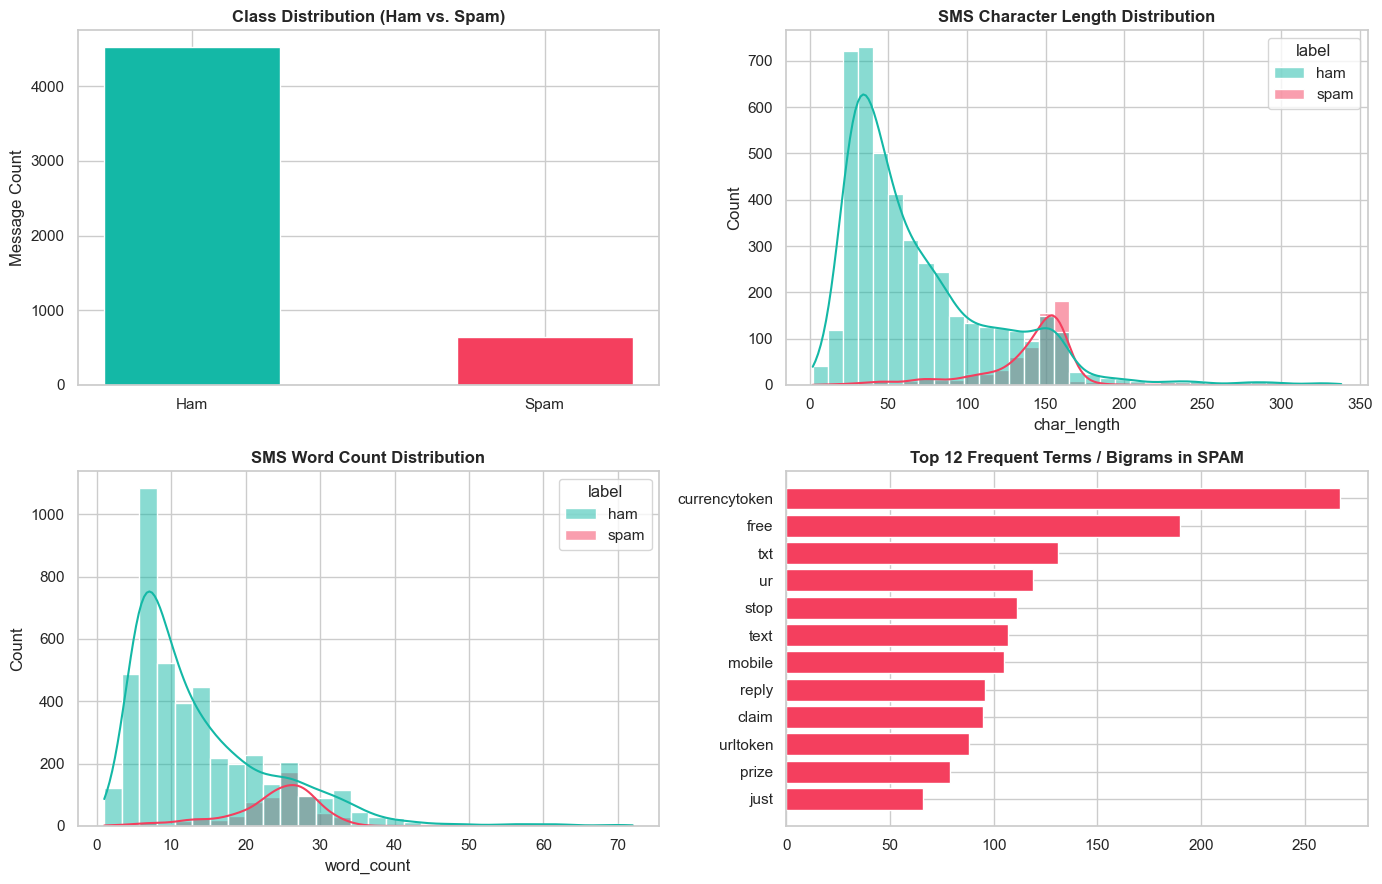

In [3]:
NEGATION_WORDS = {'no', 'not', 'never', 'none', 'nobody', 'nothing', 'neither', 'nowhere', 'cannot', 'without'}
CUSTOM_STOP_WORDS = sorted(list(ENGLISH_STOP_WORDS - NEGATION_WORDS))

def preprocess_sms_text(text: str) -> str:
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', text)
    text = re.sub(r'[£$€₹]', ' currencytoken ', text)
    text = re.sub(r"[^a-z0-9\s']", ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

palette = {'ham': '#14b8a6', 'spam': '#f43f5e'}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Class distribution
counts = df_clean['label'].value_counts()
axes[0, 0].bar(['Ham', 'Spam'], [counts['ham'], counts['spam']], color=['#14b8a6', '#f43f5e'], width=0.5)
axes[0, 0].set_title('Class Distribution (Ham vs. Spam)', fontweight='bold')
axes[0, 0].set_ylabel('Message Count')

# 2. Character Length Distribution
sns.histplot(data=df_clean[df_clean['char_length'] <= 350], x='char_length', hue='label', palette=palette, bins=35, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('SMS Character Length Distribution', fontweight='bold')

# 3. Word Count Distribution
sns.histplot(data=df_clean[df_clean['word_count'] <= 75], x='word_count', hue='label', palette=palette, bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('SMS Word Count Distribution', fontweight='bold')

# 4. Top 12 Frequent Spam Terms
vec_eda = TfidfVectorizer(preprocessor=preprocess_sms_text, stop_words=CUSTOM_STOP_WORDS, ngram_range=(1, 2), max_features=2000)
analyzer = vec_eda.build_analyzer()
spam_counter = Counter()
for m in df_clean[df_clean['label'] == 'spam']['message']:
    spam_counter.update(analyzer(m))
top_spam = pd.DataFrame(spam_counter.most_common(12), columns=['term', 'count'])[::-1]
axes[1, 1].barh(top_spam['term'], top_spam['count'], color='#f43f5e')
axes[1, 1].set_title('Top 12 Frequent Terms / Bigrams in SPAM', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Stratified 60/20/20 Split, v1.0 Baseline & Hybrid TF-IDF Engineering
We fit both the **Word TF-IDF** (1,500 features) and **Character N-Gram TF-IDF** (1,200 features, 3–5 chars) strictly on the training split to prevent data leakage.

In [4]:
X = df_clean['message'].values
y = df_clean['target'].values
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)
print(f'Split Sizes -> Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}')

# Helper functions for evaluation & validation threshold tuning
def find_optimal_threshold(y_true, scores):
    best_t, best_f1 = 0.50, -1.0
    for t in np.arange(0.25, 0.76, 0.01):
        f1 = f1_score(y_true, (scores >= t).astype(int), pos_label=1, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, float(t)
    return round(best_t, 2)

def evaluate_scores(y_true, scores, threshold=0.50):
    preds = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_true, preds)
    return {
        'threshold': threshold,
        'accuracy': round(float(accuracy_score(y_true, preds)), 4),
        'precision': round(float(precision_score(y_true, preds, pos_label=1, zero_division=0)), 4),
        'recall': round(float(recall_score(y_true, preds, pos_label=1, zero_division=0)), 4),
        'f1_score': round(float(f1_score(y_true, preds, pos_label=1, zero_division=0)), 4),
        'roc_auc': round(float(roc_auc_score(y_true, scores)), 4),
        'pr_auc': round(float(average_precision_score(y_true, scores)), 4),
        'cm': cm,
        'fp': int(cm[0, 1]),
        'fn': int(cm[1, 0]),
        'fpr_rate': round(float(cm[0, 1] / max(1, cm[0, 0] + cm[0, 1])), 4),
        'fnr_rate': round(float(cm[1, 0] / max(1, cm[1, 0] + cm[1, 1])), 4)
    }

# v1.0 Baseline (Word TF-IDF + Random Forest at fixed 0.50 cutoff)
v1_vec = TfidfVectorizer(preprocessor=preprocess_sms_text, stop_words=CUSTOM_STOP_WORDS, max_features=1500, ngram_range=(1, 2), min_df=2, sublinear_tf=True, dtype=np.float32)
v1_rf = RandomForestClassifier(n_estimators=150, min_samples_split=4, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)
v1_rf.fit(v1_vec.fit_transform(X_train), y_train)
v1_baseline = evaluate_scores(y_test, v1_rf.predict_proba(v1_vec.transform(X_test))[:, 1], threshold=0.50)
print(f"v1.0 Baseline (Word TF-IDF RF) -> Test Acc: {v1_baseline['accuracy']*100:.2f}% | Spam F1: {v1_baseline['f1_score']:.4f}")

# v2.0 Hybrid TF-IDF (Word + Character N-Grams)
word_tfidf = TfidfVectorizer(preprocessor=preprocess_sms_text, stop_words=CUSTOM_STOP_WORDS, max_features=1500, ngram_range=(1, 2), min_df=2, sublinear_tf=True, dtype=np.float32)
char_tfidf = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), max_features=1200, min_df=3, sublinear_tf=True, dtype=np.float32)
X_train_hyb = hstack([word_tfidf.fit_transform(X_train), char_tfidf.fit_transform(X_train)]).tocsr()
X_val_hyb = hstack([word_tfidf.transform(X_val), char_tfidf.transform(X_val)]).tocsr()
X_test_hyb = hstack([word_tfidf.transform(X_test), char_tfidf.transform(X_test)]).tocsr()
all_feature_names = list(word_tfidf.get_feature_names_out()) + [f'char:{c}' for c in char_tfidf.get_feature_names_out()]
print(f'v2.0 Hybrid Feature Matrix Shape: {X_train_hyb.shape}')

Split Sizes -> Train: 3096 | Validation: 1032 | Test: 1032
v1.0 Baseline (Word TF-IDF RF) -> Test Acc: 98.16% | Spam F1: 0.9237
v2.0 Hybrid Feature Matrix Shape: (3096, 2700)


## 4. Training 8 Classifiers, Validation Threshold Tuning & Soft-Voting Meta-Ensemble
We compare Decision Tree (Entropy), Logistic Regression, Calibrated Linear SVM, Random Forest, AdaBoost, Gradient Boosting, XGBoost, and a Weighted Soft-Voting Meta-Ensemble.

In [5]:
ada_sig = inspect.signature(AdaBoostClassifier.__init__).parameters
ada_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
ada_kwargs = {'n_estimators': 100, 'learning_rate': 0.8, 'random_state': RANDOM_STATE}
ada_kwargs['estimator' if 'estimator' in ada_sig else 'base_estimator'] = ada_tree
if 'algorithm' in ada_sig:
    ada_kwargs['algorithm'] = 'SAMME'

models_dict = {
    'decision_tree': ('Decision Tree (Entropy)', DecisionTreeClassifier(criterion='entropy', max_depth=25, min_samples_split=5, class_weight='balanced', random_state=RANDOM_STATE)),
    'logistic_regression': ('Logistic Regression', LogisticRegression(C=2.0, max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    'svm': ('Support Vector Machine (SVM)', CalibratedClassifierCV(LinearSVC(C=1.0, class_weight='balanced', random_state=RANDOM_STATE), cv=3)),
    'random_forest': ('Random Forest', RandomForestClassifier(n_estimators=200, min_samples_split=4, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)),
    'adaboost': ('AdaBoost', AdaBoostClassifier(**ada_kwargs)),
    'gradient_boosting': ('Gradient Boosting (GBM)', GradientBoostingClassifier(n_estimators=140, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=RANDOM_STATE)),
    'xgboost': ('XGBoost', XGBClassifier(n_estimators=180, learning_rate=0.08, max_depth=5, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.5, eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1))
}

sample_weights = compute_sample_weight('balanced', y=y_train)
trained_models, val_probs, test_probs, results_store, rows = {}, {}, {}, {}, []

for m_id, (m_name, est) in models_dict.items():
    if m_id in {'adaboost', 'gradient_boosting', 'xgboost'}:
        est.fit(X_train_hyb, y_train, sample_weight=sample_weights)
    else:
        est.fit(X_train_hyb, y_train)
    trained_models[m_id] = est
    val_probs[m_id] = est.predict_proba(X_val_hyb)[:, 1]
    test_probs[m_id] = est.predict_proba(X_test_hyb)[:, 1]
    t_opt = find_optimal_threshold(y_val, val_probs[m_id])
    val_m = evaluate_scores(y_val, val_probs[m_id], t_opt)
    test_m = evaluate_scores(y_test, test_probs[m_id], t_opt)
    results_store[m_id] = {'name': m_name, 'val': val_m, 'test': test_m, 'scores': test_probs[m_id]}
    rows.append({'Model': m_name, 'Tuned Cutoff': t_opt, 'Val F1': val_m['f1_score'], 'Test Acc': test_m['accuracy'], 'Precision': test_m['precision'], 'Recall': test_m['recall'], 'Test F1': test_m['f1_score'], 'ROC-AUC': test_m['roc_auc'], 'PR-AUC': test_m['pr_auc']})

# 8th Model: Weighted Soft-Voting Meta-Ensemble
val_vote = 0.35*val_probs['svm'] + 0.25*val_probs['logistic_regression'] + 0.20*val_probs['random_forest'] + 0.20*val_probs['xgboost']
test_vote = 0.35*test_probs['svm'] + 0.25*test_probs['logistic_regression'] + 0.20*test_probs['random_forest'] + 0.20*test_probs['xgboost']
t_vote = find_optimal_threshold(y_val, val_vote)
val_vm = evaluate_scores(y_val, val_vote, t_vote)
test_vm = evaluate_scores(y_test, test_vote, t_vote)
results_store['soft_voting'] = {'name': 'Soft-Voting Meta-Ensemble', 'val': val_vm, 'test': test_vm, 'scores': test_vote}
rows.append({'Model': 'Soft-Voting Meta-Ensemble', 'Tuned Cutoff': t_vote, 'Val F1': val_vm['f1_score'], 'Test Acc': test_vm['accuracy'], 'Precision': test_vm['precision'], 'Recall': test_vm['recall'], 'Test F1': test_vm['f1_score'], 'ROC-AUC': test_vm['roc_auc'], 'PR-AUC': test_vm['pr_auc']})

comp_df = pd.DataFrame(rows)
champ_id = max(results_store.keys(), key=lambda k: (results_store[k]['val']['f1_score'], results_store[k]['val']['pr_auc']))
champ_info = results_store[champ_id]
print(f"Selected Champion via Validation Spam F1: {champ_info['name']} (Val F1={champ_info['val']['f1_score']:.4f}, Test F1={champ_info['test']['f1_score']:.4f})")
display(comp_df)

C:\Users\bhave\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


Selected Champion via Validation Spam F1: Soft-Voting Meta-Ensemble (Val F1=0.9486, Test F1=0.9647)


,Model,Tuned Cutoff,Val F1,Test Acc,Precision,Recall,Test F1,ROC-AUC,PR-AUC
0,Decision Tree (Entropy),0.25,0.8605,0.9641,0.8227,0.9062,0.8625,0.9440,0.8107
1,Logistic Regression,0.49,0.9421,0.9884,0.9394,0.9688,0.9538,0.9932,0.9868
2,Support Vector Machine (SVM),0.34,0.9412,0.9884,0.9462,0.9609,0.9535,0.9935,0.9882
3,Random Forest,0.43,0.9344,0.9835,0.9664,0.8984,0.9312,0.9901,0.9745
4,AdaBoost,0.51,0.9163,0.9835,0.9370,0.9297,0.9333,0.9891,0.9712
5,Gradient Boosting (GBM),0.60,0.9350,0.9835,0.9664,0.8984,0.9312,0.9932,0.9760
6,XGBoost,0.56,0.9312,0.9826,0.9508,0.9062,0.9280,0.9915,0.9742
7,Soft-Voting Meta-Ensemble,0.44,0.9486,0.9913,0.9685,0.9609,0.9647,0.9932,0.9883


## 5. Model Comparison Chart & Before vs. After (v1.0 vs. v2.0) Gain

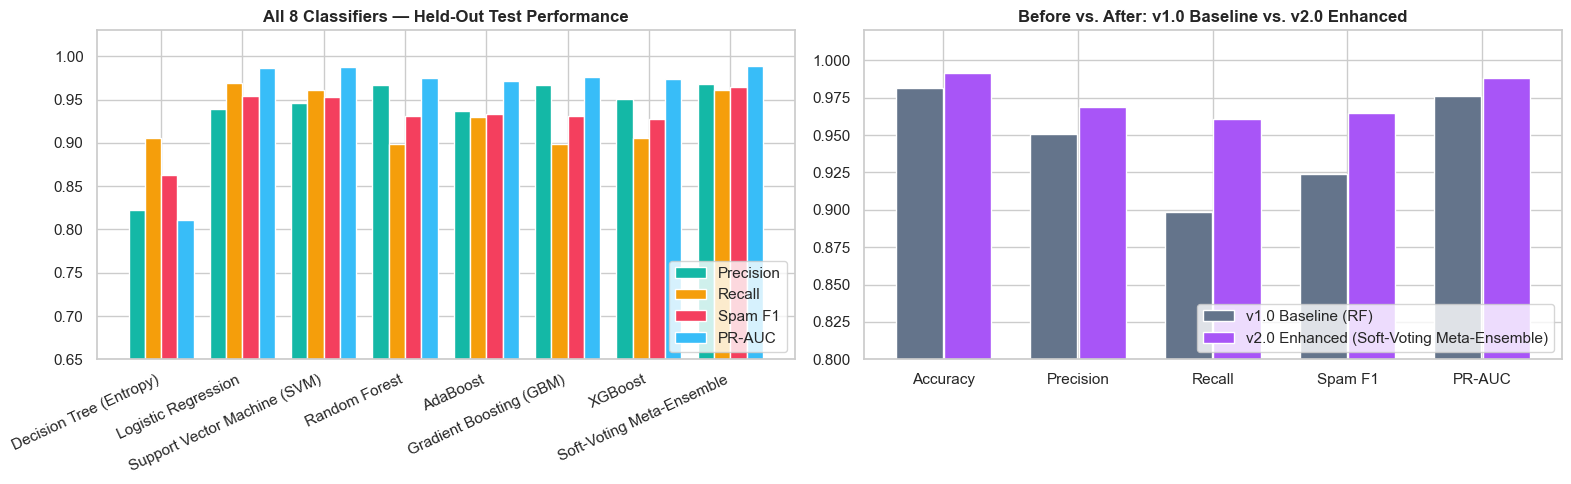

,Version,Accuracy,Spam F1,PR-AUC,False Positives,False Negatives
0,v1.0 Baseline (Word TF-IDF + RF),0.9816,0.9237,0.9764,6,13
1,v2.0 Enhanced (Soft-Voting Meta-Ensemble),0.9913,0.9647,0.9883,4,5


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# All 8 Models Comparison
x = np.arange(len(comp_df))
w = 0.2
axes[0].bar(x - 1.5*w, comp_df['Precision'], w, label='Precision', color='#14b8a6')
axes[0].bar(x - 0.5*w, comp_df['Recall'], w, label='Recall', color='#f59e0b')
axes[0].bar(x + 0.5*w, comp_df['Test F1'], w, label='Spam F1', color='#f43f5e')
axes[0].bar(x + 1.5*w, comp_df['PR-AUC'], w, label='PR-AUC', color='#38bdf8')
axes[0].set_xticks(x)
axes[0].set_xticklabels(comp_df['Model'], rotation=25, ha='right')
axes[0].set_ylim(0.65, 1.03)
axes[0].set_title('All 8 Classifiers — Held-Out Test Performance', fontweight='bold')
axes[0].legend(loc='lower right')

# v1.0 vs v2.0 Benchmark
v2_res = champ_info['test']
m_labels = ['Accuracy', 'Precision', 'Recall', 'Spam F1', 'PR-AUC']
v1_vals = [v1_baseline['accuracy'], v1_baseline['precision'], v1_baseline['recall'], v1_baseline['f1_score'], v1_baseline['pr_auc']]
v2_vals = [v2_res['accuracy'], v2_res['precision'], v2_res['recall'], v2_res['f1_score'], v2_res['pr_auc']]
xb = np.arange(len(m_labels))
axes[1].bar(xb - 0.18, v1_vals, 0.35, label='v1.0 Baseline (RF)', color='#64748b')
axes[1].bar(xb + 0.18, v2_vals, 0.35, label=f"v2.0 Enhanced ({champ_info['name']})", color='#a855f7')
axes[1].set_xticks(xb)
axes[1].set_xticklabels(m_labels)
axes[1].set_ylim(0.80, 1.02)
axes[1].set_title('Before vs. After: v1.0 Baseline vs. v2.0 Enhanced', fontweight='bold')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

bench_df = pd.DataFrame([
    {'Version': 'v1.0 Baseline (Word TF-IDF + RF)', 'Accuracy': v1_baseline['accuracy'], 'Spam F1': v1_baseline['f1_score'], 'PR-AUC': v1_baseline['pr_auc'], 'False Positives': v1_baseline['fp'], 'False Negatives': v1_baseline['fn']},
    {'Version': f"v2.0 Enhanced ({champ_info['name']})", 'Accuracy': v2_res['accuracy'], 'Spam F1': v2_res['f1_score'], 'PR-AUC': v2_res['pr_auc'], 'False Positives': v2_res['fp'], 'False Negatives': v2_res['fn']}
])
display(bench_df)

## 6. Champion Model Deep-Dive: Confusion Matrix, ROC/PR Curves & Global Feature Importance

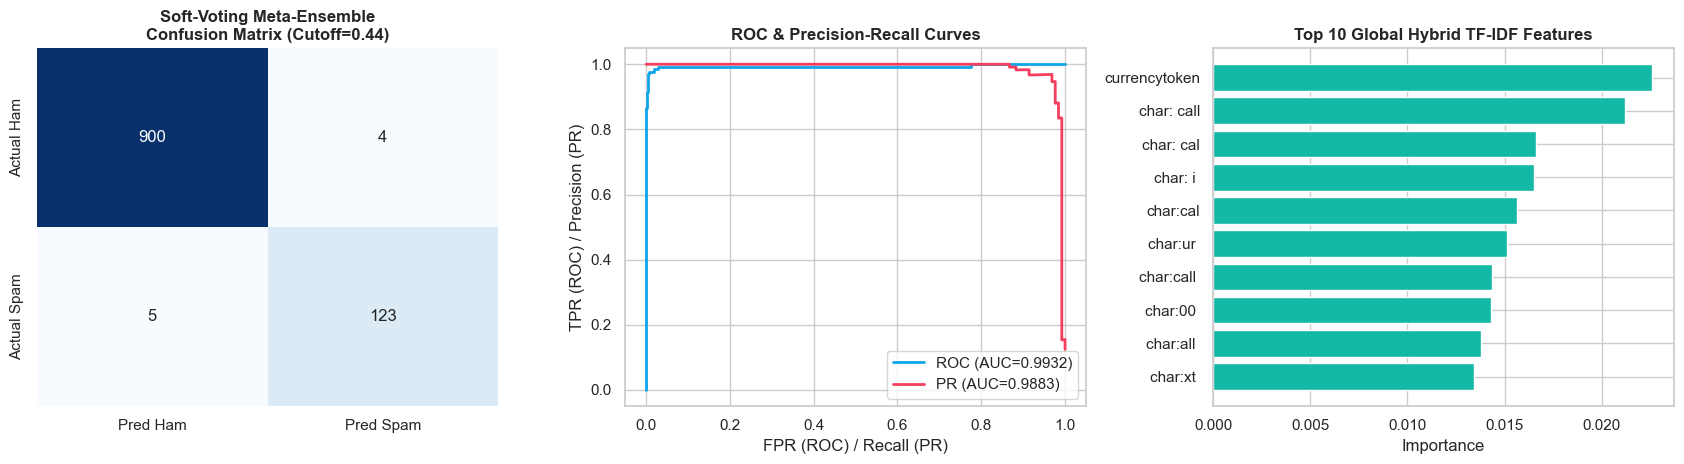

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Confusion Matrix
sns.heatmap(v2_res['cm'], annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Ham', 'Pred Spam'], yticklabels=['Actual Ham', 'Actual Spam'], ax=axes[0])
axes[0].set_title(f"{champ_info['name']}\nConfusion Matrix (Cutoff={v2_res['threshold']})", fontweight='bold')

# ROC & PR Curves
fpr, tpr, _ = roc_curve(y_test, champ_info['scores'])
prec_c, rec_c, _ = precision_recall_curve(y_test, champ_info['scores'])
axes[1].plot(fpr, tpr, color='#0ea5e9', lw=2, label=f"ROC (AUC={v2_res['roc_auc']})")
axes[1].plot(rec_c, prec_c, color='#f43f5e', lw=2, label=f"PR (AUC={v2_res['pr_auc']})")
axes[1].set_title('ROC & Precision-Recall Curves', fontweight='bold')
axes[1].set_xlabel('FPR (ROC) / Recall (PR)')
axes[1].set_ylabel('TPR (ROC) / Precision (PR)')
axes[1].legend()

# Global Feature Importance (Random Forest / Tree features)
rf_imp = trained_models['random_forest'].feature_importances_
top_idx = np.argsort(rf_imp)[::-1][:10][::-1]
axes[2].barh([all_feature_names[i] for i in top_idx], [rf_imp[i] for i in top_idx], color='#14b8a6')
axes[2].set_title('Top 10 Global Hybrid TF-IDF Features', fontweight='bold')
axes[2].set_xlabel('Importance')

plt.tight_layout()
plt.show()

## 7. Unsupervised Learning: PCA 2D Projection & K-Means Elbow Clustering
Principal Component Analysis (PCA) visualizes Ham vs. Spam separation in 2D, while K-Means + Elbow Method discovers hidden spam themes automatically.

C:\Users\bhave\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\bhave\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\bhave\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\bhave\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

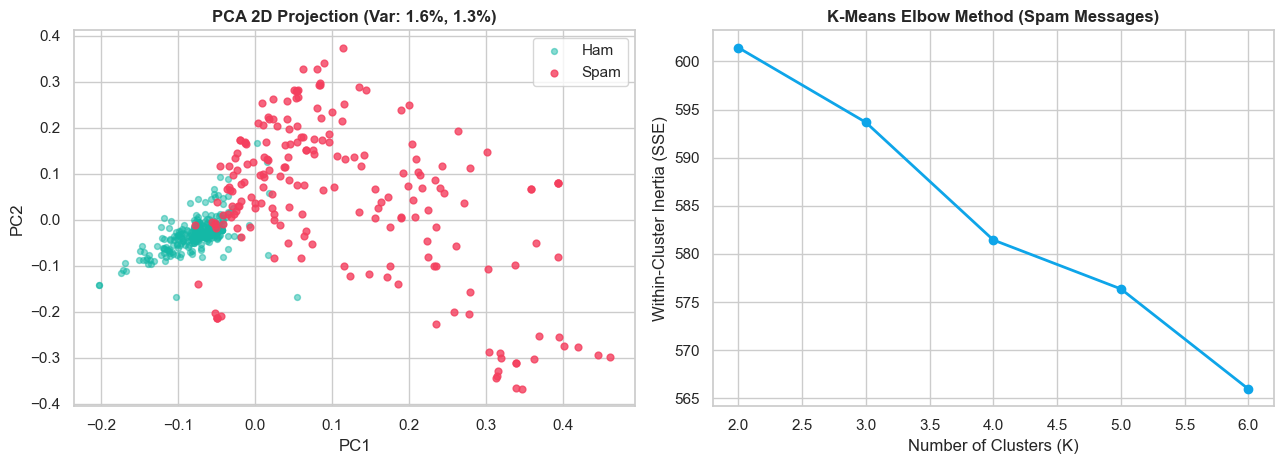

,Cluster,Messages,Top Keywords
0,Spam Cluster #1,315,"stop, urltoken, reply, text, service, new, 150p"
1,Spam Cluster #2,193,"currencytoken, prize, claim, cash, won, urgent..."
2,Spam Cluster #3,134,"free, mobile, nokia, text, txt, tone, reply"


In [8]:
# 1. PCA 2D projection on stratified sample
samp_ham = df_clean[df_clean['target'] == 0].sample(n=300, random_state=RANDOM_STATE)
samp_spam = df_clean[df_clean['target'] == 1].sample(n=200, random_state=RANDOM_STATE)
samp_df = pd.concat([samp_ham, samp_spam], ignore_index=True)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(word_tfidf.transform(samp_df['message']).toarray())

# 2. K-Means Elbow on Spam Messages
X_spam_vec = word_tfidf.transform(df_clean[df_clean['target'] == 1]['message'])
k_vals = [2, 3, 4, 5, 6]
inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_spam_vec).inertia_ for k in k_vals]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ham_mask = samp_df['target'] == 0
axes[0].scatter(coords[ham_mask, 0], coords[ham_mask, 1], c='#14b8a6', alpha=0.5, s=18, label='Ham')
axes[0].scatter(coords[~ham_mask, 0], coords[~ham_mask, 1], c='#f43f5e', alpha=0.8, s=24, label='Spam')
axes[0].set_title(f'PCA 2D Projection (Var: {pca.explained_variance_ratio_[0]*100:.1f}%, {pca.explained_variance_ratio_[1]*100:.1f}%)', fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

axes[1].plot(k_vals, inertias, marker='o', color='#0ea5e9', lw=2)
axes[1].set_title('K-Means Elbow Method (Spam Messages)', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Within-Cluster Inertia (SSE)')
plt.tight_layout()
plt.show()

# K=3 Spam Sub-Clusters
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_spam_vec)
vocab = word_tfidf.get_feature_names_out()
clusters = []
for cid in range(3):
    top_kw = [vocab[i] for i in np.argsort(km3.cluster_centers_[cid])[::-1][:7]]
    clusters.append({'Cluster': f'Spam Cluster #{cid+1}', 'Messages': int((km3.labels_ == cid).sum()), 'Top Keywords': ', '.join(top_kw)})
display(pd.DataFrame(clusters))

## 8. Reinforcement Learning (Q-Learning Screening Agent) & AI Ethics Audit
The Q-Learning agent learns an optimal screening policy (`allow_ham`, `quarantine_review`, `block_spam`) across 3 risk states using the Bellman Equation.

In [9]:
RL_STATES = ['low_risk', 'borderline_risk', 'high_risk']
RL_ACTIONS = ['allow_ham', 'quarantine_review', 'block_spam']

def get_rl_state(score):
    return 'low_risk' if score < 0.35 else ('borderline_risk' if score < 0.70 else 'high_risk')

alpha, gamma = 0.15, 0.80
q_table = {s: {a: 0.0 for a in RL_ACTIONS} for s in RL_STATES}
reward_map = {
    (0, 'allow_ham'): 10.0, (0, 'quarantine_review'): -2.0, (0, 'block_spam'): -15.0,
    (1, 'allow_ham'): -12.0, (1, 'quarantine_review'): 4.0, (1, 'block_spam'): 10.0
}

champ_val_scores = val_vote if champ_id == 'soft_voting' else val_probs[champ_id]
for _ in range(3):
    for true_lbl, sc in zip(y_val, champ_val_scores):
        st = get_rl_state(float(sc))
        for act in RL_ACTIONS:
            r = reward_map[(int(true_lbl), act)]
            q_table[st][act] = round(q_table[st][act] + alpha * (r + gamma * max(q_table[st].values()) - q_table[st][act]), 3)

q_df = pd.DataFrame(q_table).T
q_df['best_policy'] = q_df.idxmax(axis=1)
print('Learned Q-Learning Policy Table:')
display(q_df)

print('\n--- AI Ethics (Bias & Privacy) Audit ---')
print(f"False Positive Rate (Ham wrongly blocked): {v2_res['fpr_rate']*100:.2f}%")
print(f"False Negative Rate (Spam missed as Ham):  {v2_res['fnr_rate']*100:.2f}%")
print('Privacy Guarantee: 100% local execution, zero cloud API calls, zero SMS storage.')

Learned Q-Learning Policy Table:


,allow_ham,quarantine_review,block_spam,best_policy
low_risk,49.984,37.984,24.984,allow_ham
borderline_risk,5.258,8.326,5.662,quarantine_review
high_risk,27.984,43.984,49.984,block_spam



--- AI Ethics (Bias & Privacy) Audit ---
False Positive Rate (Ham wrongly blocked): 0.44%
False Negative Rate (Spam missed as Ham):  3.91%
Privacy Guarantee: 100% local execution, zero cloud API calls, zero SMS storage.


## 9. Rule-Based Warning Signs & Live Multi-Case Screening Demo
Testing legitimate Ham, urgent phishing Spam, and heavily obfuscated Spam (`f.r.e.e`, `w1n`, `c@sh`).

In [10]:
WARNING_RULES = [
    ('Link / Shortened URL', re.compile(r'(https?://\S+|www\.\S+|\b(?:bit\.ly|tinyurl\.com)/\S+)', re.I)),
    ('Urgent Pressure Language', re.compile(r'\b(urgent|immediately|act now|account suspended|within \d+ hours)\b', re.I)),
    ('Prize / Reward Lure', re.compile(r'\b(congratulations|you have won|winner|cash prize|voucher|free gift)\b', re.I)),
    ('OTP / Banking Credential Request', re.compile(r'\b(otp|pin|cvv|bank account|verify.*kyc|password)\b', re.I)),
    ('Financial / Currency Pattern', re.compile(r'([£$€₹]\s?\d+|\bcall\s+09\d{8,10}\b)', re.I))
]

def predict_live_sms(text):
    X_hyb = hstack([word_tfidf.transform([text]), char_tfidf.transform([text])]).tocsr()
    if champ_id == 'soft_voting':
        score = (0.35*trained_models['svm'].predict_proba(X_hyb)[0,1]
                 + 0.25*trained_models['logistic_regression'].predict_proba(X_hyb)[0,1]
                 + 0.20*trained_models['random_forest'].predict_proba(X_hyb)[0,1]
                 + 0.20*trained_models['xgboost'].predict_proba(X_hyb)[0,1])
    else:
        score = float(trained_models[champ_id].predict_proba(X_hyb)[0, 1])
    label = 'SPAM' if score >= v2_res['threshold'] else 'HAM'
    st = get_rl_state(score)
    act = max(q_table[st], key=q_table[st].get)
    signs = [name for name, pat in WARNING_RULES if pat.search(text)]
    return {
        'SMS Message': text[:68] + ('...' if len(text) > 68 else ''),
        'Prediction': label,
        'Spam Score (%)': round(score * 100, 1),
        'Q-Agent Action': act,
        'Warning Signs': ', '.join(signs) if signs else 'None'
    }

samples = [
    'Hi Mum, I reached college safely. My project presentation is at 2:30 PM.',
    'URGENT: Your bank account is suspended. Click http://bit.ly/verify-kyc and enter your OTP.',
    'C0ngrats!! U have w1n a f.r.e.e $500 c@sh voucher! Cl@im urgent at bit.ly/freecash99 now!'
]
display(pd.DataFrame([predict_live_sms(s) for s in samples]))

,SMS Message,Prediction,Spam Score (%),Q-Agent Action,Warning Signs
0,"Hi Mum, I reached college safely. My project p...",HAM,4.3,allow_ham,None
1,URGENT: Your bank account is suspended. Click ...,SPAM,58.6,quarantine_review,"Link / Shortened URL, Urgent Pressure Language..."
2,C0ngrats!! U have w1n a f.r.e.e $500 c@sh vouc...,SPAM,57.0,quarantine_review,"Link / Shortened URL, Urgent Pressure Language..."
